# Telco Customer Churn: Prediction and Retention-Campaign ROI

**Business context:** A telecom company loses ~1 in 4 customers. Retention offers cost money, so the real question is not
*"can we predict churn?"* but ***"who should we spend retention budget on, and does that make money?"***

This notebook goes from raw data to a **profit-maximising targeting policy**, with the checks an interviewer will probe:
leakage, honest validation, calibration, interpretability, and sensitivity to business assumptions.

| Step | What / why |
|---|---|
| 1. Data audit | Public IBM Telco sample dataset (7,043 customers of a fictional telco; a standard benchmark). Fix data issues, confirm no leakage |
| 2. EDA | Which segments churn most? |
| 3. Modelling | Logistic regression vs gradient boosting, tuned with cross-validation on the **train set only** |
| 4. Honest test | One final evaluation on a held-out test set; ROC-AUC, PR-AUC, calibration |
| 5. Interpretation | Odds ratios + permutation importance |
| 6. Business decision | Expected-profit targeting vs "do nothing", "contact everyone" and a simple rule; bootstrap CIs; sensitivity |

**Data source:** IBM sample dataset *Telco Customer Churn* (publicly available). Currency is US dollars.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
IMG = "../images/"; SEED = 42; rng = np.random.default_rng(SEED)

## 1. Data audit

In [2]:
raw = pd.read_csv("../data/telco_churn.csv")
print("Shape:", raw.shape, "| duplicate customers:", raw.customerID.duplicated().sum(), "| missing cells:", int(raw.isna().sum().sum()))
bad = pd.to_numeric(raw.TotalCharges.str.strip(), errors="coerce").isna()
print(f"TotalCharges is stored as text; {bad.sum()} values are blank. Who are they?")
display(raw.loc[bad, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head())

Shape: (7043, 21) | duplicate customers: 0 | missing cells: 0
TotalCharges is stored as text; 11 values are blank. Who are they?


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No


**Finding:** all 11 blank `TotalCharges` belong to customers with `tenure = 0` (just signed up, not billed yet), so the correct value is **0**,
not a mean/median imputation. Churn rate by this group is 0%.

In [3]:
df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df.TotalCharges.str.strip(), errors="coerce").fillna(0.0)
df["y"] = (df.Churn == "Yes").astype(int)
print(f"Churn rate: {df.y.mean():.1%}  ({df.y.sum():,} of {len(df):,})")
r = np.corrcoef(df.TotalCharges, df.tenure * df.MonthlyCharges)[0, 1]
print(f"corr(TotalCharges, tenure x MonthlyCharges) = {r:.3f}  -> TotalCharges is almost a deterministic function of two other columns")

Churn rate: 26.5%  (1,869 of 7,043)
corr(TotalCharges, tenure x MonthlyCharges) = 1.000  -> TotalCharges is almost a deterministic function of two other columns


**Modelling decisions made here, before looking at any model score**
* `customerID` dropped (identifier). `TotalCharges` dropped (redundant, r > 0.99 with tenure x monthly; it also adds collinearity to the linear model).
* `gender` dropped: no signal, and it is a protected attribute that should not drive who receives retention offers.
* No column describes what happens *after* churn (e.g. a cancellation reason), so there is no target leakage.
* `SeniorCitizen` is kept but flagged: age-based targeting should be reviewed with legal/compliance before production use.

## 2. Who churns? (EDA)

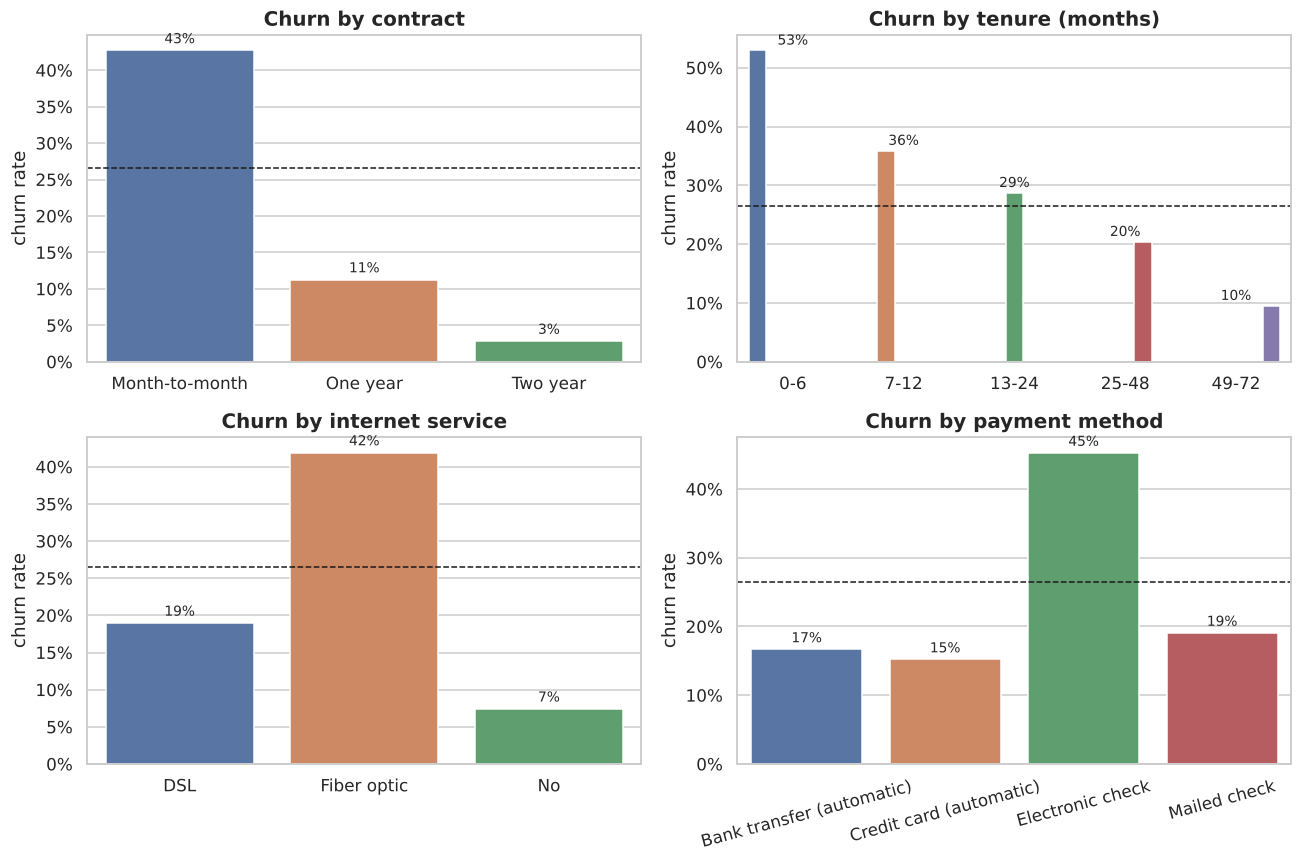

Month-to-month customers: 55% of base but 89% of all churners


In [4]:
def churn_by(col, ax, order=None, title=None):
    t = df.groupby(col).y.agg(["mean", "size"]).reset_index()
    if order: t = t.set_index(col).loc[order].reset_index()
    sns.barplot(data=t, x=col, y="mean", hue=col, legend=False, ax=ax)
    ax.axhline(df.y.mean(), c="k", ls="--", lw=1); ax.set_ylabel("churn rate"); ax.set_xlabel("")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_title(title or col)
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])): ax.text(i, m + .01, f"{m:.0%}", ha="center", fontsize=9)
df["tenure_band"] = pd.cut(df.tenure, [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
churn_by("Contract", ax[0, 0], ["Month-to-month", "One year", "Two year"], "Churn by contract")
churn_by("tenure_band", ax[0, 1], None, "Churn by tenure (months)")
churn_by("InternetService", ax[1, 0], ["DSL", "Fiber optic", "No"], "Churn by internet service")
churn_by("PaymentMethod", ax[1, 1], None, "Churn by payment method"); ax[1, 1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig(IMG + "01_churn_drivers.png"); plt.show()
mtm = df[df.Contract == "Month-to-month"]
print(f"Month-to-month customers: {len(mtm)/len(df):.0%} of base but {mtm.y.sum()/df.y.sum():.0%} of all churners")

**Reading:** churn is concentrated in **month-to-month contracts, new customers (first 6 months), fibre-optic internet and electronic-check payers**.
These are associations, not causes - e.g. fibre customers may churn because of price or competitor offers, which this data cannot separate.

## 3. Modelling - with honest validation
* A **stratified 80/20 split** is made once. The 20% test set is not touched until the final evaluation.
* Model selection and tuning use **5-fold stratified cross-validation on the training set only**.
* Metrics: **ROC-AUC** (ranking quality) and **PR-AUC / average precision** (better under class imbalance, baseline = churn rate).

In [5]:
num_cols = ["tenure", "MonthlyCharges", "SeniorCitizen"]
cat_cols = ["Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]
X, y = df[num_cols + cat_cols], df.y
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"train {len(Xtr):,} (churn {ytr.mean():.1%})  |  test {len(Xte):,} (churn {yte.mean():.1%})")
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
def pre(): return ColumnTransformer([("num", StandardScaler(), num_cols), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)])
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}

# 1) baseline that ignores features
base = cross_validate(DummyClassifier(strategy="prior"), Xtr, ytr, cv=skf, scoring=scoring)
# 2) logistic regression, tune regularisation
lr_gs = GridSearchCV(Pipeline([("pre", pre()), ("clf", LogisticRegression(max_iter=3000))]),
                     {"clf__C": [0.03, 0.1, 0.3, 1, 3]}, cv=skf, scoring="roc_auc", n_jobs=-1).fit(Xtr, ytr)
# 3) gradient boosting, small grid
hgb_gs = GridSearchCV(Pipeline([("pre", pre()), ("clf", HistGradientBoostingClassifier(max_iter=400, early_stopping=True,
                      n_iter_no_change=20, validation_fraction=0.1, random_state=SEED))]),
                      {"clf__learning_rate": [0.03, 0.06], "clf__max_depth": [2, 3, 4], "clf__min_samples_leaf": [20, 60], "clf__l2_regularization": [1.0]},
                      cv=skf, scoring="roc_auc", n_jobs=-1).fit(Xtr, ytr)
cv = {}
for name, gs in [("Logistic regression", lr_gs), ("Gradient boosting", hgb_gs)]:
    r = cross_validate(gs.best_estimator_, Xtr, ytr, cv=skf, scoring=scoring); cv[name] = r
rows = [("Baseline (prior)", base)] + list(cv.items())
cvtab = pd.DataFrame([{"model": n, "CV ROC-AUC": r["test_roc_auc"].mean(), "± sd": r["test_roc_auc"].std(), "CV PR-AUC": r["test_pr_auc"].mean()} for n, r in rows]).set_index("model")
display(cvtab.round(3))
print("Best LR params :", lr_gs.best_params_); print("Best HGB params:", hgb_gs.best_params_)

train 5,634 (churn 26.5%)  |  test 1,409 (churn 26.5%)


,CV ROC-AUC,± sd,CV PR-AUC
model,,,
Baseline (prior),0.500,0.000,0.265
Logistic regression,0.845,0.012,0.660
Gradient boosting,0.850,0.012,0.668


Best LR params : {'clf__C': 1}
Best HGB params: {'clf__l2_regularization': 1.0, 'clf__learning_rate': 0.03, 'clf__max_depth': 2, 'clf__min_samples_leaf': 20}


In [6]:
gap = cvtab.loc["Gradient boosting", "CV ROC-AUC"] - cvtab.loc["Logistic regression", "CV ROC-AUC"]
# decision rule fixed in advance: prefer the simpler, interpretable model unless boosting is clearly better
chosen_name = "Gradient boosting" if gap > 0.005 else "Logistic regression"
model = (hgb_gs if chosen_name == "Gradient boosting" else lr_gs).best_estimator_
print(f"Boosting - LR CV ROC-AUC gap = {gap:+.4f}  ->  chosen model: {chosen_name} (rule: pick the simpler model unless boosting wins by > 0.005)")

Boosting - LR CV ROC-AUC gap = +0.0050  ->  chosen model: Logistic regression (rule: pick the simpler model unless boosting wins by > 0.005)


## 4. Final, one-time evaluation on the held-out test set

,ROC-AUC,PR-AUC,Brier
Logistic regression,0.839,0.630,0.139
Gradient boosting,0.845,0.666,0.135
Baseline (prior),0.500,0.265,0.195


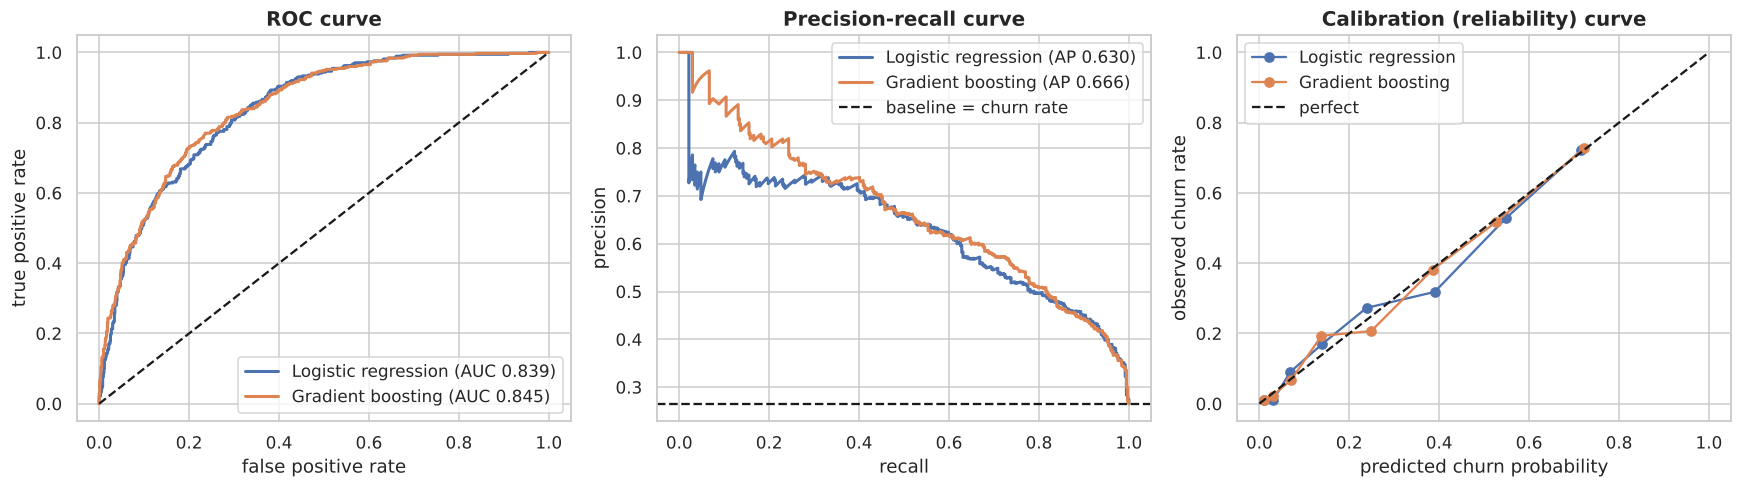

In [7]:
models = {"Logistic regression": lr_gs.best_estimator_, "Gradient boosting": hgb_gs.best_estimator_}
P = {n: m.predict_proba(Xte)[:, 1] for n, m in models.items()}
res = pd.DataFrame({n: {"ROC-AUC": roc_auc_score(yte, p), "PR-AUC": average_precision_score(yte, p), "Brier": brier_score_loss(yte, p)} for n, p in P.items()}).T
res.loc["Baseline (prior)"] = [0.5, yte.mean(), brier_score_loss(yte, np.full(len(yte), ytr.mean()))]
display(res.round(3)); p_te = P[chosen_name]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for n, p in P.items():
    f, t, _ = roc_curve(yte, p); ax[0].plot(f, t, lw=2, label=f"{n} (AUC {roc_auc_score(yte, p):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p); ax[1].plot(rc, pr, lw=2, label=f"{n} (AP {average_precision_score(yte, p):.3f})")
    pt, pp = calibration_curve(yte, p, n_bins=8, strategy="quantile"); ax[2].plot(pp, pt, marker="o", label=n)
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC curve"); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate"); ax[0].legend(loc="lower right")
ax[1].axhline(yte.mean(), c="k", ls="--", label="baseline = churn rate"); ax[1].set_title("Precision-recall curve"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].legend()
ax[2].plot([0, 1], [0, 1], "k--", label="perfect"); ax[2].set_title("Calibration (reliability) curve"); ax[2].set_xlabel("predicted churn probability"); ax[2].set_ylabel("observed churn rate"); ax[2].legend()
plt.tight_layout(); plt.savefig(IMG + "02_model_evaluation.png"); plt.show()

**Why calibration matters here:** the profit calculation below multiplies the predicted probability by a customer's value.
That only works if "30% predicted" really means ~30% of such customers churn. A model can rank well (high AUC) and still be miscalibrated.

## 5. What drives the predictions?

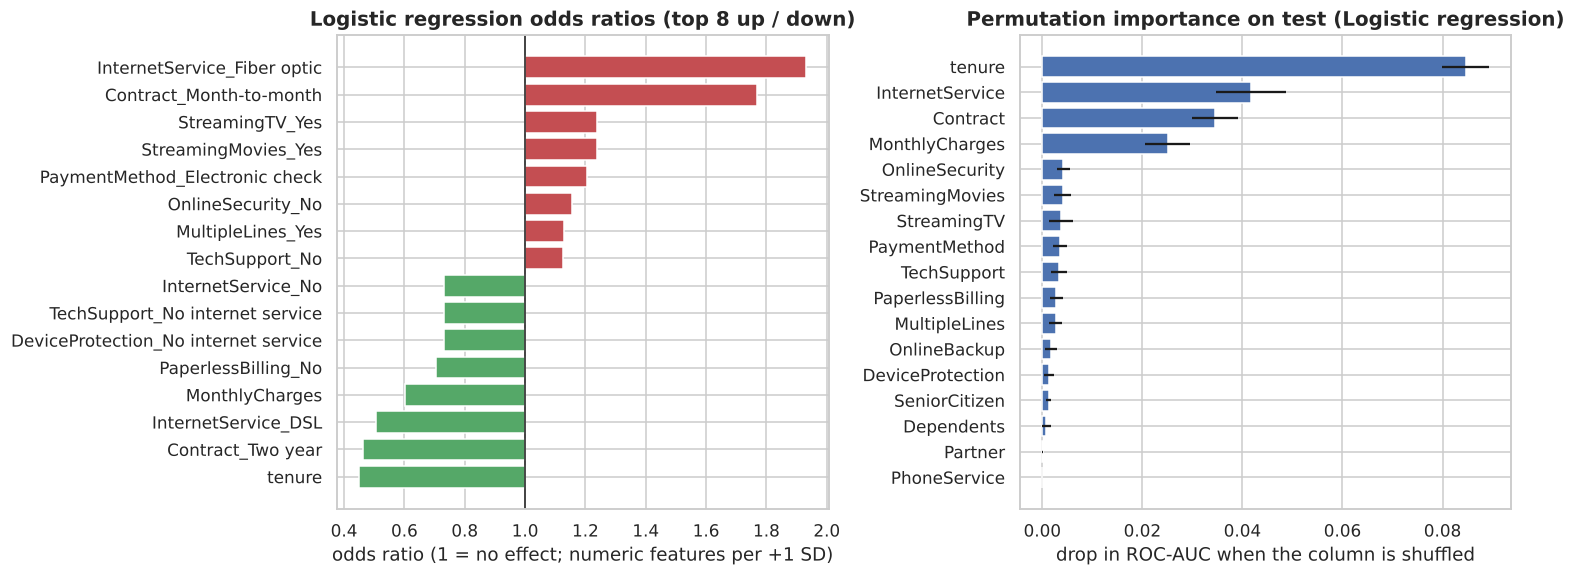

Top permutation-importance features: tenure, InternetService, Contract, MonthlyCharges, OnlineSecurity


In [8]:
lr = lr_gs.best_estimator_
names = lr.named_steps["pre"].get_feature_names_out(); coef = lr.named_steps["clf"].coef_[0]
orx = pd.DataFrame({"feature": [n.split("__", 1)[1] for n in names], "odds_ratio": np.exp(coef)}).sort_values("odds_ratio")
sel = pd.concat([orx.head(8), orx.tail(8)])
fig, ax = plt.subplots(1, 2, figsize=(14, 5.4))
ax[0].barh(sel.feature, sel.odds_ratio - 1, left=1, color=["#55a868" if v < 1 else "#c44e52" for v in sel.odds_ratio]); ax[0].axvline(1, c="k", lw=1)
ax[0].set_title("Logistic regression odds ratios (top 8 up / down)"); ax[0].set_xlabel("odds ratio (1 = no effect; numeric features per +1 SD)")
pi = permutation_importance(model, Xte, yte, scoring="roc_auc", n_repeats=15, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values()
ax[1].barh(imp.index, imp.values, xerr=pi.importances_std[[list(Xte.columns).index(c) for c in imp.index]], color="#4c72b0")
ax[1].set_title(f"Permutation importance on test ({chosen_name})"); ax[1].set_xlabel("drop in ROC-AUC when the column is shuffled")
plt.tight_layout(); plt.savefig(IMG + "03_drivers.png"); plt.show()
print("Top permutation-importance features:", ", ".join(imp.sort_values(ascending=False).index[:5]))

**Caveats:** odds ratios of correlated features (e.g. the many internet add-ons) are hard to read individually, and **none of this is causal**.
Permutation importance is computed on the test set with the whole pipeline, so it measures what the deployed model actually relies on.

## 6. From prediction to a business decision
A model score is only useful if it changes an action. We compare **who to contact with a retention offer**.

**Assumptions (all explicit and editable - an interviewer will ask where they come from):**

| Parameter | Value | Meaning |
|---|---|---|
| Offer cost `c` | USD 25 per contacted customer | discount credit + handling, paid whether or not they would have churned |
| Offer success rate `s` | 30% | share of *would-be churners* who accept and stay (assumption - should be measured by an A/B test) |
| Margin | 40% | contribution margin on revenue |
| Horizon | 12 months | value of a saved customer = monthly charge x 12 x margin |

**Expected profit of contacting customer *i*** = `P(churn)_i x s x Value_i - c`. We contact a customer only when this is positive,
which automatically gives *higher-value customers a lower probability threshold*. The `P(churn)` for the training customers comes from
**out-of-fold predictions** so nothing is evaluated on data the model has seen.

In [9]:
C, S, MARGIN, MONTHS = 25.0, 0.30, 0.40, 12
value = lambda d: d.MonthlyCharges.values * MONTHS * MARGIN           # profit from keeping the customer for 12 months
V_te = value(Xte)
p_oof = cross_val_predict(model, Xtr, ytr, cv=skf, method="predict_proba")[:, 1]    # out-of-fold, train only
V_tr = value(Xtr)

def profit(contact, y, V, s=S, c=C):
    # expected profit: would-be churners (y=1) are saved with prob s; every contacted customer costs c
    return float(np.sum(contact * (y * s * V - c)))

# policy 1: global probability threshold tuned on out-of-fold train predictions
grid = np.linspace(0.05, 0.9, 86)
prof_grid = [profit((p_oof > t).astype(float), ytr.values, V_tr) for t in grid]
t_star = grid[int(np.argmax(prof_grid))]
# policy 2: expected-value rule (needs calibrated probabilities)
ev_rule = lambda p, V, s=S, c=C: (p * s * V - c > 0).astype(float)

mtm_te = (Xte.Contract == "Month-to-month").values.astype(float)
policies = {
    "Do nothing":                      np.zeros(len(Xte)),
    "Contact everyone":                np.ones(len(Xte)),
    "Rule: month-to-month customers":  mtm_te,
    f"Model: p > {t_star:.2f} (tuned on train OOF)": (p_te > t_star).astype(float),
    "Model: expected-profit rule":     ev_rule(p_te, V_te),
}
tab = pd.DataFrame({k: {"customers contacted": int(v.sum()), "% of base": v.mean(), "churners reached": int((v * yte.values).sum()),
                        "expected profit ($)": profit(v, yte.values, V_te), "profit per 1,000 customers ($)": profit(v, yte.values, V_te) / len(Xte) * 1000}
                    for k, v in policies.items()}).T
display(tab.style.format({"customers contacted": "{:,.0f}", "% of base": "{:.0%}", "churners reached": "{:,.0f}", "expected profit ($)": "{:,.0f}", "profit per 1,000 customers ($)": "{:,.0f}"}))

,customers contacted,% of base,churners reached,expected profit ($),"profit per 1,000 customers ($)"
Do nothing,0,0%,0,0,0
Contact everyone,"1,409",100%,374,"3,964","2,814"
Rule: month-to-month customers,773,55%,329,"14,253","10,116"
Model: p > 0.27 (tuned on train OOF),566,40%,290,"17,750","12,598"
Model: expected-profit rule,555,39%,269,"17,760","12,605"


In [10]:
# uncertainty: bootstrap the TEST set to get a 95% interval on profit per 1,000 customers and the gain over the best naive policy
def per1000(v, y, V, idx): return profit(v[idx], y[idx], V[idx]) / len(idx) * 1000
yv = yte.values; B = 2000; names = list(policies)
boot = {k: np.empty(B) for k in names}
for b in range(B):
    idx = rng.integers(0, len(yv), len(yv))
    for k in names: boot[k][b] = per1000(policies[k], yv, V_te, idx)
best_model_key = "Model: expected-profit rule"
for k in names[1:]:
    lo, hi = np.percentile(boot[k], [2.5, 97.5]); pt = per1000(policies[k], yv, V_te, np.arange(len(yv)))
    print(f"{k:<46s} ${pt:>7,.0f} per 1,000   95% CI [${lo:,.0f}, ${hi:,.0f}]")
d = boot[best_model_key] - np.maximum(boot["Contact everyone"], boot["Rule: month-to-month customers"])
print(f"\nExpected-profit rule minus best naive policy: ${d.mean():,.0f} per 1,000 customers (bootstrap mean), 95% CI [${np.percentile(d,2.5):,.0f}, ${np.percentile(d,97.5):,.0f}]; "
      f"model wins in {np.mean(d > 0):.0%} of bootstrap samples")

Contact everyone                               $  2,814 per 1,000   95% CI [$160, $5,510]
Rule: month-to-month customers                 $ 10,116 per 1,000   95% CI [$7,892, $12,378]
Model: p > 0.27 (tuned on train OOF)           $ 12,598 per 1,000   95% CI [$10,442, $14,729]
Model: expected-profit rule                    $ 12,605 per 1,000   95% CI [$10,400, $14,778]

Expected-profit rule minus best naive policy: $2,496 per 1,000 customers (bootstrap mean), 95% CI [$1,589, $3,487]; model wins in 100% of bootstrap samples


In [11]:
# robustness: does the decision rule depend on which model we picked?
rob = pd.DataFrame({n: {"ROC-AUC": roc_auc_score(yte, p), "customers contacted": int(ev_rule(p, V_te).sum()),
                        "profit per 1,000 ($)": profit(ev_rule(p, V_te), yte.values, V_te) / len(Xte) * 1000} for n, p in P.items()}).T
display(rob.style.format({"ROC-AUC": "{:.3f}", "customers contacted": "{:,.0f}", "profit per 1,000 ($)": "{:,.0f}"}))

,ROC-AUC,customers contacted,"profit per 1,000 ($)"
Logistic regression,0.839,555,"12,605"
Gradient boosting,0.845,568,"12,900"


The business result is not an artefact of the model choice: both models give a similar profit under the same decision rule, so the extra complexity of boosting buys little here.

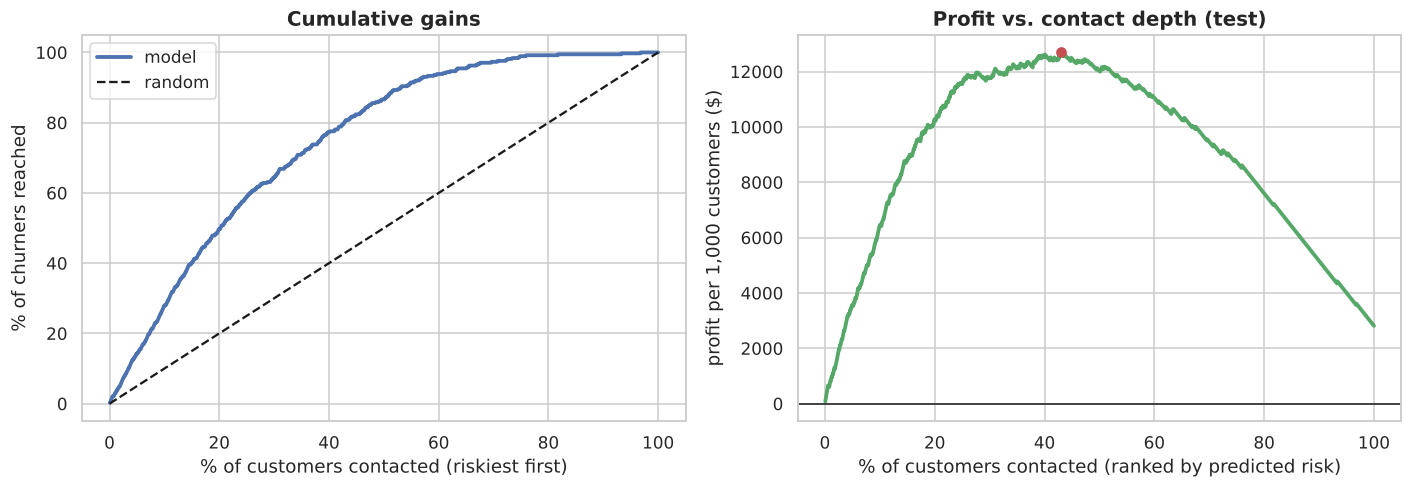

Contacting the riskiest 20% reaches 50% of churners (random would reach 20%); riskiest 30% reaches 64%.


In [12]:
# gains chart: how many churners do we reach by contacting the riskiest x% ?
order = np.argsort(-p_te); cum = np.cumsum(yte.values[order]) / yte.sum(); frac = np.arange(1, len(order) + 1) / len(order)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].plot(frac * 100, cum * 100, lw=2.5, label="model"); ax[0].plot([0, 100], [0, 100], "k--", label="random"); ax[0].set_xlabel("% of customers contacted (riskiest first)"); ax[0].set_ylabel("% of churners reached")
ax[0].set_title("Cumulative gains"); ax[0].legend()
ev_curve = np.cumsum(yte.values[order] * S * V_te[order] - C) / len(Xte) * 1000
ax[1].plot(frac * 100, ev_curve, lw=2.5, color="#55a868"); ax[1].axhline(0, c="k", lw=1); k_best = int(np.argmax(ev_curve)); ax[1].scatter(frac[k_best] * 100, ev_curve[k_best], c="r", zorder=5)
ax[1].set_xlabel("% of customers contacted (ranked by predicted risk)"); ax[1].set_ylabel("profit per 1,000 customers ($)"); ax[1].set_title("Profit vs. contact depth (test)")
plt.tight_layout(); plt.savefig(IMG + "04_gains_profit.png"); plt.show()
top20 = cum[int(len(cum) * .2) - 1]; top30 = cum[int(len(cum) * .3) - 1]
print(f"Contacting the riskiest 20% reaches {top20:.0%} of churners (random would reach 20%); riskiest 30% reaches {top30:.0%}.")

### Sensitivity: does the conclusion survive wrong assumptions?
The success rate `s` and offer cost `c` are guesses. We re-run the expected-profit rule across a grid and compare it with the best naive policy in each scenario.

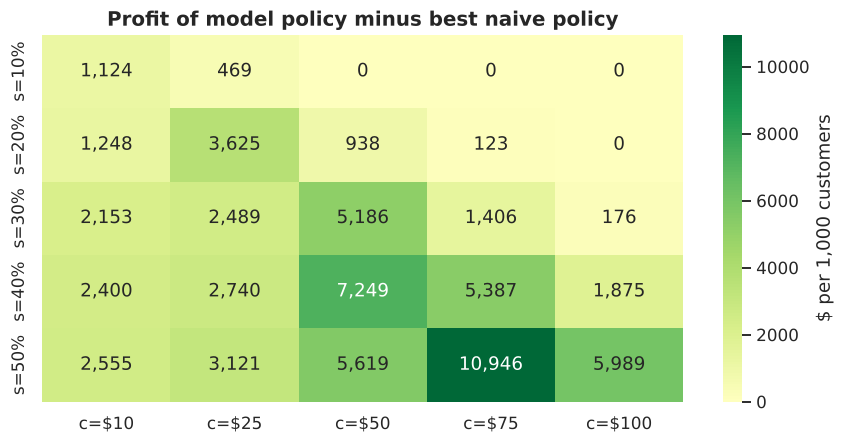

Scenarios where the model policy is worse than the best naive policy: 0 of 25


In [13]:
ss = [0.10, 0.20, 0.30, 0.40, 0.50]; cs = [10, 25, 50, 75, 100]
adv = pd.DataFrame(index=[f"s={s:.0%}" for s in ss], columns=[f"c=${c}" for c in cs], dtype=float)
for s in ss:
    for c in cs:
        pol = profit(ev_rule(p_te, V_te, s, c), yv, V_te, s, c)
        naive = max(0.0, profit(np.ones(len(yv)), yv, V_te, s, c), profit(mtm_te, yv, V_te, s, c))
        adv.loc[f"s={s:.0%}", f"c=${c}"] = (pol - naive) / len(yv) * 1000
plt.figure(figsize=(8, 4.2)); sns.heatmap(adv, annot=True, fmt=",.0f", cmap="RdYlGn", center=0, cbar_kws={"label": "$ per 1,000 customers"})
plt.title("Profit of model policy minus best naive policy"); plt.tight_layout(); plt.savefig(IMG + "05_sensitivity.png"); plt.show()
print("Scenarios where the model policy is worse than the best naive policy:", int((adv < -1e-9).sum().sum()), "of", adv.size)

**Reading the grid:** a **0** means no campaign pays off in that scenario (offer too costly relative to how often it works), and the expected-profit rule correctly
contacts nobody. Everywhere else the model-based policy beats both naive policies. The practical message: **the whole case rests on the offer success rate `s`**,
so measuring it with an experiment is the first thing to do - not building a fancier model.

### Who are the highest-risk customers?

In [14]:
te = Xte.copy(); te["p"] = p_te; te["y"] = yte.values
top = te.nlargest(len(te) // 10, "p")
prof = pd.DataFrame({"Top-10% risk": [top.Contract.eq("Month-to-month").mean(), top.InternetService.eq("Fiber optic").mean(), top.PaymentMethod.eq("Electronic check").mean(), top.tenure.median(), top.MonthlyCharges.mean(), top.y.mean()],
                     "All customers": [te.Contract.eq("Month-to-month").mean(), te.InternetService.eq("Fiber optic").mean(), te.PaymentMethod.eq("Electronic check").mean(), te.tenure.median(), te.MonthlyCharges.mean(), te.y.mean()]},
                    index=["% month-to-month", "% fibre optic", "% electronic check", "median tenure (months)", "avg monthly charge ($)", "actual churn rate"])
display(prof.style.format("{:.2f}").format("{:.0%}", subset=pd.IndexSlice[["% month-to-month", "% fibre optic", "% electronic check", "actual churn rate"], :]))

,Top-10% risk,All customers
% month-to-month,100%,55%
% fibre optic,99%,44%
% electronic check,80%,34%
median tenure (months),4.00,28.00
avg monthly charge ($),83.91,64.09
actual churn rate,74%,27%


## 7. Findings, recommendations and limitations

In [15]:
pm = tab.loc["Model: expected-profit rule"]; pa = tab.loc["Contact everyone"]; pr = tab.loc["Rule: month-to-month customers"]
lr_t = res.loc["Logistic regression"]; hg_t = res.loc["Gradient boosting"]; mt = res.loc[chosen_name]
display(Markdown(f'''
| # | Finding | Evidence |
|---|---|---|
| 1 | **Churn is concentrated in month-to-month and new customers** | Month-to-month = {len(mtm)/len(df):.0%} of customers but {mtm.y.sum()/df.y.sum():.0%} of churners; first-6-month customers churn at {df[df.tenure<=6].y.mean():.0%} |
| 2 | **Boosting is only marginally better** | Test ROC-AUC: logistic {lr_t["ROC-AUC"]:.3f} vs boosting {hg_t["ROC-AUC"]:.3f}, PR-AUC {lr_t["PR-AUC"]:.2f} vs {hg_t["PR-AUC"]:.2f}. The CV gap sat right at our pre-set 0.005 threshold, so we kept the interpretable **{chosen_name}**; either choice is defensible and the profit result is similar (see robustness table) |
| 3 | **Model is usable for money decisions** | Test PR-AUC {mt["PR-AUC"]:.2f} vs {yte.mean():.2f} baseline; Brier {mt["Brier"]:.3f} (calibration curve is close to the diagonal) |
| 4 | **Targeting beats blanket campaigns** | Per 1,000 customers: contact everyone earns USD {pa["profit per 1,000 customers ($)"]:,.0f}; the month-to-month rule USD {pr["profit per 1,000 customers ($)"]:,.0f}; the expected-profit model policy **USD {pm["profit per 1,000 customers ($)"]:,.0f}** while contacting only {pm["% of base"]:.0%} of the base. Gain over the best naive policy: USD {d.mean():,.0f} (95% bootstrap CI USD {np.percentile(d,2.5):,.0f} to {np.percentile(d,97.5):,.0f}) |
| 5 | **Reach** | Riskiest 20% of customers contain {top20:.0%} of churners; the riskiest 10% are {top.Contract.eq("Month-to-month").mean():.0%} month-to-month, {top.InternetService.eq("Fiber optic").mean():.0%} fibre, median tenure {top.tenure.median():.0f} months, and {top.y.mean():.0%} actually churned |

**Recommendations**
1. Pilot the expected-profit targeting on month-to-month, fibre-optic and electronic-check customers in their **first 12 months**.
2. **Run an A/B test** (see my A/B-testing project) with a holdout group to *measure* the offer success rate `s`. The whole profit calculation depends on it, and the sensitivity grid shows how much.
3. Test cheaper, non-discount levers for the segments driving churn: contract-upgrade incentives, automatic-payment enrolment, onboarding calls in months 1-6.
4. Re-train monthly and monitor calibration drift, not only AUC.

**Limitations (say these in the interview):** one snapshot, no time dimension, so we predict *who is likely to be a churner*, not *when*;
the offer effect is assumed, not estimated (predicting churn is not the same as predicting who is *persuadable* - that needs **uplift modelling** on experiment data);
margin/cost figures are illustrative; associations are not causal.
'''))


| # | Finding | Evidence |
|---|---|---|
| 1 | **Churn is concentrated in month-to-month and new customers** | Month-to-month = 55% of customers but 89% of churners; first-6-month customers churn at 53% |
| 2 | **Boosting is only marginally better** | Test ROC-AUC: logistic 0.839 vs boosting 0.845, PR-AUC 0.63 vs 0.67. The CV gap sat right at our pre-set 0.005 threshold, so we kept the interpretable **Logistic regression**; either choice is defensible and the profit result is similar (see robustness table) |
| 3 | **Model is usable for money decisions** | Test PR-AUC 0.63 vs 0.27 baseline; Brier 0.139 (calibration curve is close to the diagonal) |
| 4 | **Targeting beats blanket campaigns** | Per 1,000 customers: contact everyone earns USD 2,814; the month-to-month rule USD 10,116; the expected-profit model policy **USD 12,605** while contacting only 39% of the base. Gain over the best naive policy: USD 2,496 (95% bootstrap CI USD 1,589 to 3,487) |
| 5 | **Reach** | Riskiest 20% of customers contain 50% of churners; the riskiest 10% are 100% month-to-month, 99% fibre, median tenure 4 months, and 74% actually churned |

**Recommendations**
1. Pilot the expected-profit targeting on month-to-month, fibre-optic and electronic-check customers in their **first 12 months**.
2. **Run an A/B test** (see my A/B-testing project) with a holdout group to *measure* the offer success rate `s`. The whole profit calculation depends on it, and the sensitivity grid shows how much.
3. Test cheaper, non-discount levers for the segments driving churn: contract-upgrade incentives, automatic-payment enrolment, onboarding calls in months 1-6.
4. Re-train monthly and monitor calibration drift, not only AUC.

**Limitations (say these in the interview):** one snapshot, no time dimension, so we predict *who is likely to be a churner*, not *when*;
the offer effect is assumed, not estimated (predicting churn is not the same as predicting who is *persuadable* - that needs **uplift modelling** on experiment data);
margin/cost figures are illustrative; associations are not causal.
